## 1. Import the required libraries



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Read the CSV dataset



In [3]:
df = pd.read_csv("dataset.csv")

print("Dataset loaded successfully!")
print("Shape (rows, columns):", df.shape)

Dataset loaded successfully!
Shape (rows, columns): (2781, 9)


## 3. Understand the dataset


In [4]:
display(df.head())

,team,season,role,position,shirt_number,full_name,country,is_overseas,birthdate
0,FC Barcelona,2022/2023,Player,Goalkeeper,1.0,Marc-André ter Stegen,Germany,1,1992-04-30
1,FC Barcelona,2022/2023,Player,Defender,4.0,Ronald Araújo,Uruguay,1,1999-03-07
2,FC Barcelona,2022/2023,Player,Midfielder,5.0,Busquets,Spain,0,1988-07-16
3,FC Barcelona,2022/2023,Player,Midfielder,6.0,Gavi,Spain,0,2004-08-05
4,FC Barcelona,2022/2023,Player,Forward,7.0,Ousmane Dembélé,France,1,1997-05-15


In [5]:
display(df.tail())

,team,season,role,position,shirt_number,full_name,country,is_overseas,birthdate
2776,FC Barcelona,1901/1902,Player,Forward,NaN,Hans Gamper,Switzerland,1,1877-11-22
2777,FC Barcelona,1901/1902,Player,Midfielder,NaN,Udo Steinberg,Germany,1,1877-06-13
2778,FC Barcelona,1901/1902,Player,Midfielder,NaN,José Quirante,Spain,0,1884-01-01
2779,FC Barcelona,1900/1901,Player,Forward,NaN,Hans Gamper,Switzerland,1,1877-11-22
2780,FC Barcelona,1899/1900,Player,Forward,NaN,Hans Gamper,Switzerland,1,1877-11-22


### Column names and data types

In [6]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types:")
print(df.dtypes)

Column names:
['team', 'season', 'role', 'position', 'shirt_number', 'full_name', 'country', 'is_overseas', 'birthdate']
\nData types:
team                str
season              str
role                str
position            str
shirt_number    float64
full_name           str
country             str
is_overseas       int64
birthdate           str
dtype: object


### Dataset information

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2781 entries, 0 to 2780
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   team          2781 non-null   str    
 1   season        2781 non-null   str    
 2   role          2781 non-null   str    
 3   position      2781 non-null   str    
 4   shirt_number  833 non-null    float64
 5   full_name     2781 non-null   str    
 6   country       2781 non-null   str    
 7   is_overseas   2781 non-null   int64  
 8   birthdate     2740 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 195.7 KB


### Statistical summary

In [8]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
team,2781,1,FC Barcelona,2781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,2781,124,2021/2022,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
role,2781,2,Player,2557,NaN,NaN,NaN,NaN,NaN,NaN,NaN
position,2781,9,Midfielder,854,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shirt_number,833.0,NaN,NaN,NaN,17.917167,10.947058,1.0,8.0,17.0,26.0,46.0
full_name,2781,788,Busquets,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,2781,59,Spain,2054,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_overseas,2781.0,NaN,NaN,NaN,0.261417,0.439485,0.0,0.0,0.0,1.0,1.0
birthdate,2740,764,1934-03-08,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data understanding and quality checks



In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

print("\\nMissing values in each column:")
display(df.isnull().sum().to_frame(name="Missing values"))

Number of duplicate rows: 0
\nMissing values in each column:


,Missing values
team,0
season,0
role,0
position,0
shirt_number,1948
full_name,0
country,0
is_overseas,0
birthdate,41


## 5. Data transformation

We will:
1. Convert `birthdate` from text to a datetime data type.
2. Extract the starting year from `season`.
3. Create an estimated `player_age` for each season using the season's starting year and the player's birth year.
4. Convert `is_overseas` into a readable category.

The age is an estimate at the start of the season, not the player's exact age on every date in that season.

In [10]:
# Work on a copy so that the original data remains unchanged
df_clean = df.copy()

# Convert birthdate into datetime format
df_clean["birthdate"] = pd.to_datetime(df_clean["birthdate"], errors="coerce")

# Extract the first year from season, for example "2022/2023" -> 2022
df_clean["season_start_year"] = pd.to_numeric(
    df_clean["season"].astype(str).str[:4],
    errors="coerce"
)

# Extract birth year
df_clean["birth_year"] = df_clean["birthdate"].dt.year

# Estimate player's age at the start of that season
df_clean["player_age"] = df_clean["season_start_year"] - df_clean["birth_year"]

# Convert 0/1 values into readable labels
df_clean["overseas_status"] = df_clean["is_overseas"].map({
    1: "Overseas",
    0: "Domestic"
})

display(df_clean[[
    "full_name", "season", "birthdate",
    "season_start_year", "player_age", "overseas_status"
]].head())

print("Data transformation completed.")

,full_name,season,birthdate,season_start_year,player_age,overseas_status
0,Marc-André ter Stegen,2022/2023,1992-04-30,2022,30.0,Overseas
1,Ronald Araújo,2022/2023,1999-03-07,2022,23.0,Overseas
2,Busquets,2022/2023,1988-07-16,2022,34.0,Domestic
3,Gavi,2022/2023,2004-08-05,2022,18.0,Domestic
4,Ousmane Dembélé,2022/2023,1997-05-15,2022,25.0,Overseas


Data transformation completed.


## 6. Handling null values using mean imputation



In [11]:
print("Missing values before imputation:")
display(df_clean.isnull().sum().to_frame(name="Missing values"))

Missing values before imputation:


,Missing values
team,0
season,0
role,0
position,0
shirt_number,1948
full_name,0
country,0
is_overseas,0
birthdate,58
season_start_year,0


In [12]:

mean_age = df_clean["player_age"].mean()

print("Mean player age:", round(mean_age, 2))


df_clean["player_age"] = df_clean["player_age"].fillna(mean_age)

print("\\nMissing player_age values after imputation:",
      df_clean["player_age"].isnull().sum())

Mean player age: 26.69
\nMissing player_age values after imputation: 0


In [13]:
print("Missing values after imputation:")
display(df_clean.isnull().sum().to_frame(name="Missing values"))

Missing values after imputation:


,Missing values
team,0
season,0
role,0
position,0
shirt_number,1948
full_name,0
country,0
is_overseas,0
birthdate,58
season_start_year,0


## 7. Insight generation


- Which playing positions occur most often?
- Which countries contribute the most players?
- How many squad records are present in each season?
- What is the domestic versus overseas split?
- What is the average estimated player age by position?

### Insight 1: Number of records by playing position

In [14]:
position_counts = df_clean["position"].value_counts()
display(position_counts.to_frame(name="Number of records"))

print("Most common position:", position_counts.idxmax())
print("Number of records in that position:", position_counts.max())

,Number of records
position,
Midfielder,854
Forward,720
Defender,714
Goalkeeper,269
Manager,105
Ass. Manager,62
Goalkeeping Coach,25
Athletic Coach,20
Game Analyst,12


Most common position: Midfielder
Number of records in that position: 854


### Insight 2: Top 10 countries

In [15]:
country_counts = df_clean["country"].value_counts().head(10)
display(country_counts.to_frame(name="Number of records"))

print("Country with the most records:", country_counts.idxmax())

,Number of records
country,
Spain,2054
Netherlands,116
Brazil,90
Argentina,88
France,56
Uruguay,40
Germany,38
Hungary,37
England,29


Country with the most records: Spain


### Insight 3: Squad records by season

In [16]:
season_counts = (
    df_clean.groupby("season")["full_name"]
    .count()
    .sort_index()
)
display(season_counts.to_frame(name="Squad records"))

,Squad records
season,
1899/1900,1
1900/1901,1
1901/1902,3
1902/1903,3
1903/1904,3
...,...
2018/2019,41
2019/2020,37
2020/2021,38


### Insight 4: Domestic and overseas records

In [17]:
overseas_counts = df_clean["overseas_status"].value_counts()
display(overseas_counts.to_frame(name="Number of records"))

overseas_percentage = (
    df_clean["is_overseas"].mean() * 100
)
print("Percentage of overseas records:", round(overseas_percentage, 2), "%")

,Number of records
overseas_status,
Domestic,2054
Overseas,727


Percentage of overseas records: 26.14 %


### Insight 5: Average estimated age by position

In [18]:
average_age_position = (
    df_clean.groupby("position")["player_age"]
    .mean()
    .sort_values(ascending=False)
)
display(average_age_position.to_frame(name="Average estimated age"))

,Average estimated age
position,
Goalkeeping Coach,44.200000
Ass. Manager,44.124039
Manager,44.095917
Athletic Coach,44.084521
Game Analyst,43.500000
Goalkeeper,26.347141
Defender,25.669000
Forward,24.742789
Midfielder,24.732713


## 8. Data visualization



### Chart 1: Records by playing position

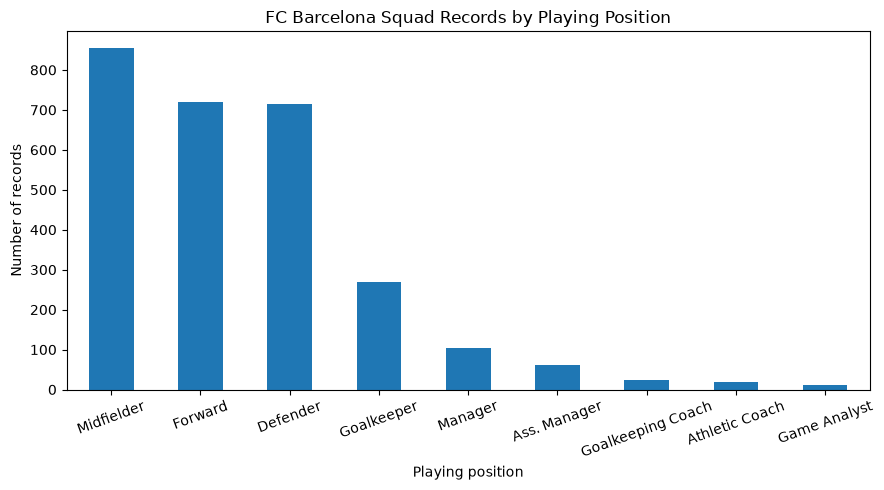

In [19]:
plt.figure(figsize=(9, 5))
position_counts.plot(kind="bar")
plt.title("FC Barcelona Squad Records by Playing Position")
plt.xlabel("Playing position")
plt.ylabel("Number of records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Chart 2: Top 10 countries

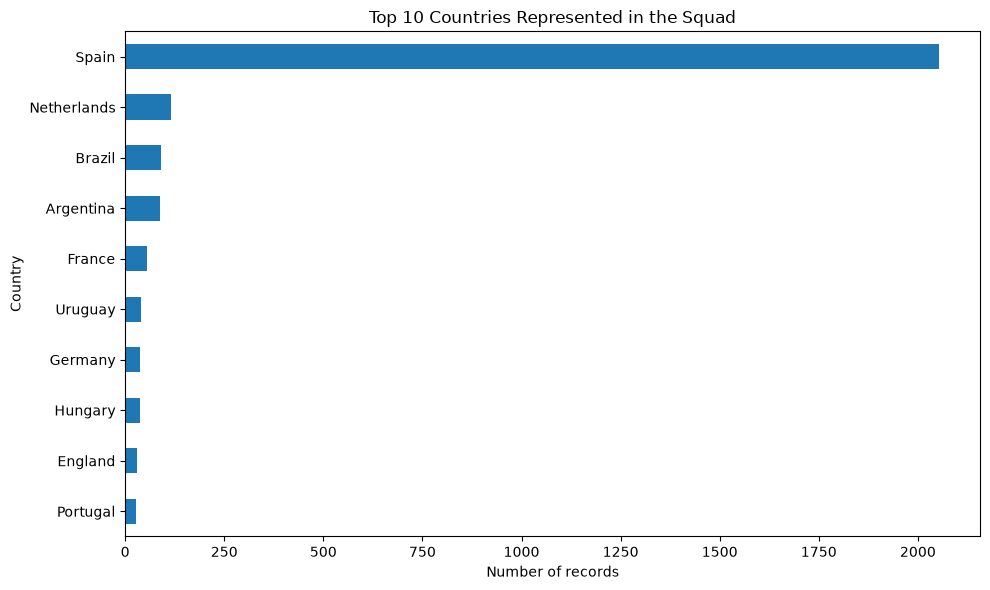

In [20]:
plt.figure(figsize=(10, 6))
country_counts.sort_values().plot(kind="barh")
plt.title("Top 10 Countries Represented in the Squad")
plt.xlabel("Number of records")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Chart 3: Squad records by season

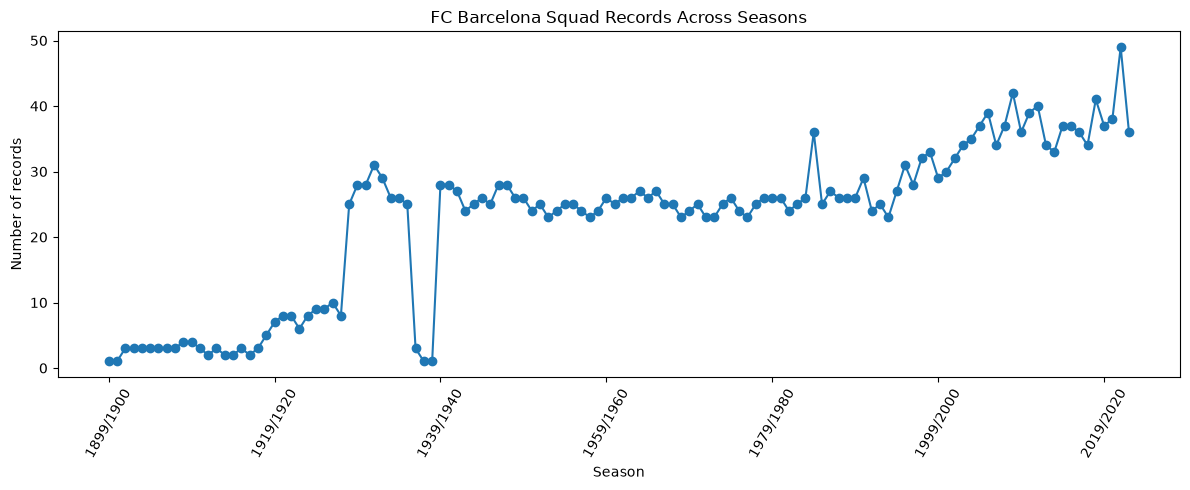

In [21]:
plt.figure(figsize=(12, 5))
season_counts.plot(kind="line", marker="o")
plt.title("FC Barcelona Squad Records Across Seasons")
plt.xlabel("Season")
plt.ylabel("Number of records")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

### Chart 4: Domestic versus overseas records

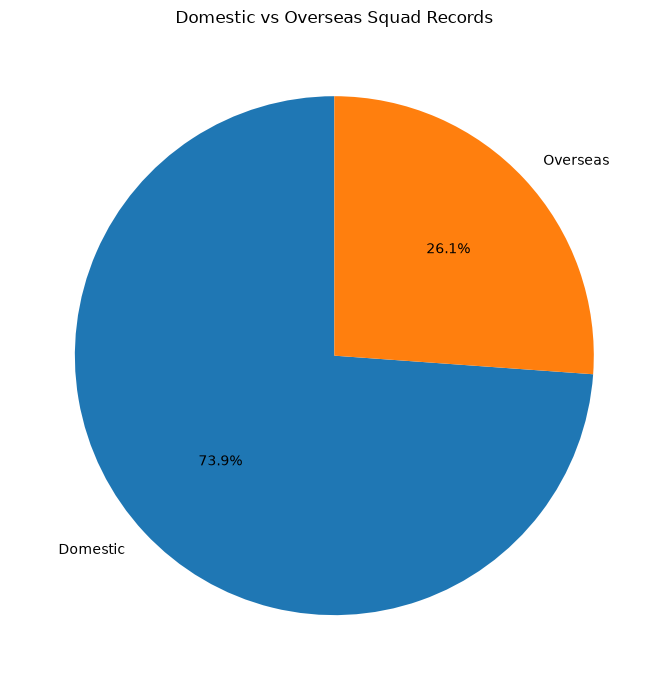

In [22]:
plt.figure(figsize=(7, 7))
overseas_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Domestic vs Overseas Squad Records")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Chart 5: Distribution of estimated player age

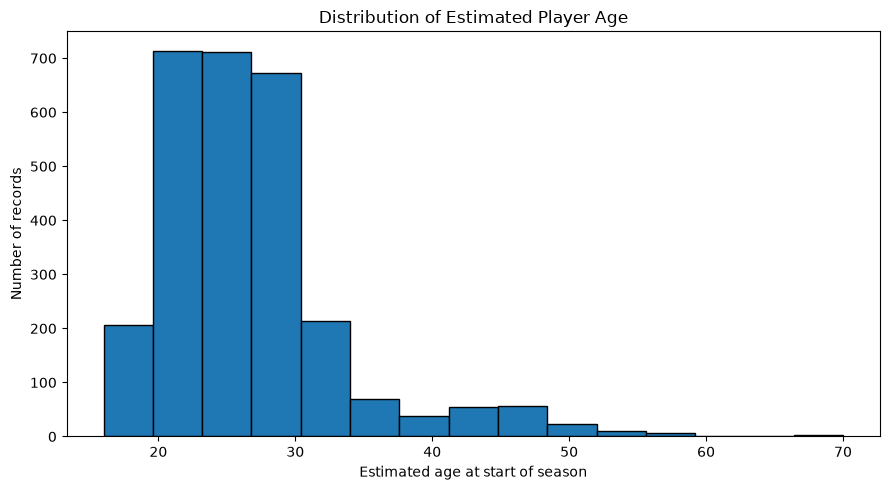

In [23]:
plt.figure(figsize=(9, 5))
df_clean["player_age"].plot(kind="hist", bins=15, edgecolor="black")
plt.title("Distribution of Estimated Player Age")
plt.xlabel("Estimated age at start of season")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

### Chart 6: Average estimated age by position

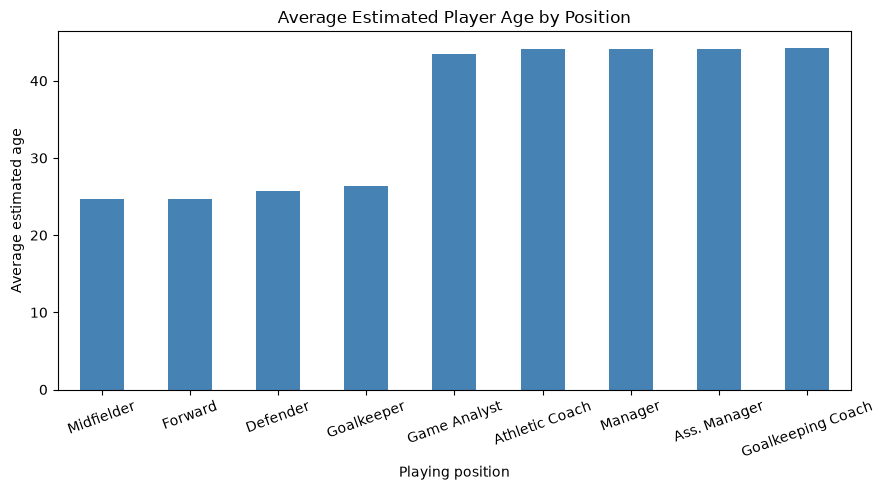

In [24]:
plt.figure(figsize=(9, 5))
average_age_position.sort_values().plot(kind="bar", color="steelblue")
plt.title("Average Estimated Player Age by Position")
plt.xlabel("Playing position")
plt.ylabel("Average estimated age")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 9. Final observations and conclusion

Run the cell below to print a short summary based on the dataset.

In [25]:
print("FINAL SUMMARY")
print("-" * 45)
print("Total records:", len(df_clean))
print("Total columns after transformation:", len(df_clean.columns))
print("Most common playing position:", position_counts.idxmax())
print("Country with the most records:", country_counts.idxmax())
print("Mean estimated player age after imputation:", round(df_clean["player_age"].mean(), 2))
print("Overseas records (%):", round(overseas_percentage, 2))
print("-" * 45)
print("Mean imputation was applied to missing player_age values.")
print("Missing shirt numbers were retained because shirt numbers are identifiers.")

FINAL SUMMARY
---------------------------------------------
Total records: 2781
Total columns after transformation: 13
Most common playing position: Midfielder
Country with the most records: Spain
Mean estimated player age after imputation: 26.69
Overseas records (%): 26.14
---------------------------------------------
Mean imputation was applied to missing player_age values.
Missing shirt numbers were retained because shirt numbers are identifiers.
